#### Load Packages

In [1]:
suppressMessages(library(tidyverse))

source("./Manuscript_files/theme_ggplot_cfrna.R")

In [2]:
passQC_meta <- read.delim("./Manuscript_files/sample_metadata.tsv")

#### Plotting Code

Warning message:
“Removed 13 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range
(`stat_summary()`).”


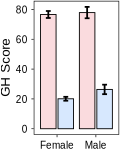

In [3]:
# GENERAL HEALTH CASE AND CONTROL
plot_name <- "GH_bar"
yaxis <- "GH Score"

passQC_meta$GH <- as.numeric(passQC_meta$GH)

width = 1
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

# Create the plot
plot_me <- ggplot(passQC_meta, aes(x = sex, y = GH, fill = phenotype)) + 
    stat_summary(fun = mean, geom = "bar", position = position_dodge(width = 0.9), width = 0.8, color = "black", lwd = 0.25) +
    stat_summary(fun.data = mean_se, geom = "errorbar", position = position_dodge(width = 0.9), width = 0.25) +
    scale_fill_manual(values = COLORS_FILL) + 
    scale_x_discrete(labels = c("F" = "Female", "M" = "Male")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = yaxis, fill = "Phenotype")

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [4]:
width = 1.5
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 33 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 33 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”


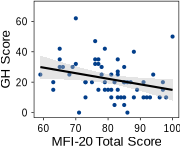

In [5]:
# GH AND MFI-20 SCORES (only phenotype == "MECFS")
plot_name <- "gh_mfi20_correlation_mecfs"

passQC_meta$GH <- as.numeric(passQC_meta$GH)
passQC_meta$mfi20_total <- as.numeric(passQC_meta$mfi20_total)

# Subset data for MECFS only
passQC_meta_cases <- passQC_meta %>% filter(phenotype == "MECFS")

# Create the plot
plot_me <- ggplot(passQC_meta_cases, aes(x = mfi20_total, y = GH, color = phenotype)) +
  geom_point(size = 0.5) +  
  geom_smooth(method = "lm", se = TRUE, fill = "gray", color = "black", lwd = .6) + 
  labs(x = "MFI-20 Total Score", y = "GH Score") +
  scale_color_manual(values = COLORS) +
  scale_y_continuous(limits = c(0, 70), breaks = seq(0, 80, by = 20)) + 
  theme_cfrna_paper() 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

Warning message:
“Removed 79 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 79 rows containing non-finite outside the scale range (`stat_bin()`).”


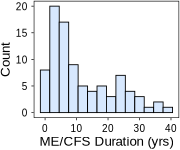

In [6]:
# DISEASE DURATION
plot_name <- "duration_hist"

plot_me <- ggplot(passQC_meta, aes(x = mecfs_duration)) +
  geom_histogram(binwidth = 3, fill = "#D7E8FE", color = "black", lwd = 0.25) +   #  fill = "#34B5FF"  (darker blue)
  labs(x = "ME/CFS Duration (yrs)", y = "Count") +
  theme_cfrna_paper() 
  
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


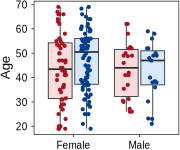

In [7]:
# AGE DISTRIBUTION
plot_name <- "age_distribution"
yaxis <- "Age"

passQC_meta$age <- as.numeric(passQC_meta$age)

# Create the plot
plot_me <- ggplot(passQC_meta, aes(x = sex, y = age, fill = phenotype)) +
    geom_boxplot(width = 0.8, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.15), alpha = 1, size = 0.5) +
    scale_color_manual(values = COLORS) +
    scale_fill_manual(values = COLORS_FILL) + 
    scale_x_discrete(labels = c("F" = "Female", "M" = "Male")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = yaxis, fill = "Phenotype", color = "Phenotype") 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

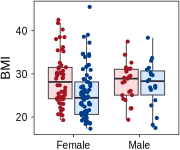

In [8]:
# BMI DISTRIBUTION
plot_name <- "bmi_distribution"
yaxis <- "BMI"

passQC_meta$bmi <- as.numeric(passQC_meta$bmi)

# Create the plot
plot_me <- ggplot(passQC_meta, aes(x = sex, y = bmi, fill = phenotype)) +
    geom_boxplot(width = 0.8, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.15), alpha = 1, size = 0.5) +
    scale_color_manual(values = COLORS) +
    scale_fill_manual(values = COLORS_FILL) + 
    scale_x_discrete(labels = c("F" = "Female", "M" = "Male")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = yaxis, fill = "Phenotype", color = "Phenotype") 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

Warning message:
“Removed 49 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 49 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 49 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 49 rows containing missing values or values outside the scale range
(`geom_point()`).”


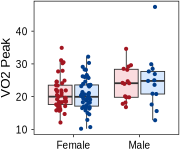

In [9]:
# VO2 PEAK DISTRIBUTION
plot_name <- "vo2_distribution"
yaxis <- "VO2 Peak"

passQC_meta$vo2peak1 <- as.numeric(passQC_meta$vo2peak1)

# Create the plot
plot_me <- ggplot(passQC_meta, aes(x = sex, y = vo2peak1, fill = phenotype)) +
    geom_boxplot(width = 0.8, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.15), alpha = 1, size = 0.5) +
    scale_color_manual(values = COLORS) +
    scale_fill_manual(values = COLORS_FILL) + 
    scale_x_discrete(labels = c("F" = "Female", "M" = "Male")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = yaxis, fill = "Phenotype", color = "Phenotype") 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [10]:
width = 1.2
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

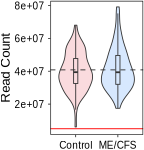

In [11]:
# READS ALL
plot_name <- "reads_all"
var <- passQC_meta$reads_all

plot_me <- ggplot(passQC_meta, aes(x = phenotype, y = var, fill = phenotype)) +
    geom_violin(trim = TRUE, width = 0.8, lwd = 0.25) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = "Read Count", fill = "Phenotype", color = "Phenotype") +
    geom_boxplot(width = 0.1, outlier.shape = NA, lwd = 0.25) +
       geom_hline(yintercept=mean(var, na.rm=TRUE), linetype="dashed", color="gray20", linewidth = 0.25) +
   geom_hline(yintercept=5000000, color="red", linewidth = 0.25)

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

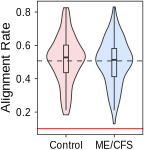

In [12]:
# ALIGNMENT RATE
plot_name <- "unique_input_ratio"
var <- passQC_meta$unique_input_ratio

plot_me <- ggplot(passQC_meta, aes(x = phenotype, y = var, fill = phenotype)) +
    geom_violin(trim = TRUE, width = 0.8, lwd = 0.25) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = "Alignment Rate", fill = "Phenotype", color = "Phenotype") +
    geom_boxplot(width = 0.1, outlier.shape = NA, lwd = 0.25) +
   geom_hline(yintercept=mean(var, na.rm=TRUE), linetype="dashed", color="gray20", linewidth = 0.25) +
   geom_hline(yintercept=0.1, color="red", linewidth = 0.25) 
    
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

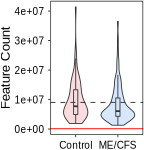

In [13]:
# FEATURE COUNTS
plot_name <- "ftcounts"
var <- passQC_meta$ftcount

plot_me <- ggplot(passQC_meta, aes(x = phenotype, y = var, fill = phenotype)) +
    geom_violin(trim = TRUE, width = 0.8, lwd = 0.25) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = "Feature Count", fill = "Phenotype", color = "Phenotype") +
    geom_boxplot(width = 0.1, outlier.shape = NA, lwd = 0.25) +
   geom_hline(yintercept=mean(var, na.rm=TRUE), linetype="dashed", color="gray20", linewidth = 0.25) +
   geom_hline(yintercept=100000, color="red", linewidth = 0.25)  

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

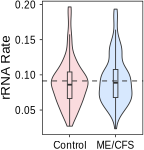

In [14]:
# rRNA RATE
plot_name <- "rRNA_rate"
var <- passQC_meta$rRNA_rate

plot_me <- ggplot(passQC_meta, aes(x = phenotype, y = var, fill = phenotype)) +
    geom_violin(trim = TRUE, width = 0.8, lwd = 0.25) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = "rRNA Rate", fill = "Phenotype", color = "Phenotype") +
    geom_boxplot(width = 0.1, outlier.shape = NA, lwd = 0.25) +
    geom_hline(yintercept=mean(var, na.rm=TRUE), linetype="dashed", color="gray20", linewidth = 0.25) 
    
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

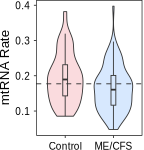

In [15]:
# mtRNA RATE
plot_name <- "mtRNA_rate"
var <- passQC_meta$mtRNA_rate

plot_me <- ggplot(passQC_meta, aes(x = phenotype, y = var, fill = phenotype)) +
    geom_violin(trim = TRUE, width = 0.8, lwd = 0.25) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(x = NULL, y = "mtRNA Rate", fill = "Phenotype", color = "Phenotype") +
    geom_boxplot(width = 0.1, outlier.shape = NA, lwd = 0.25, alpha = 0.6) +
    geom_hline(yintercept=mean(var, na.rm=TRUE), linetype="dashed", color="gray20", linewidth = 0.25) +
    theme(plot.margin = margin(0, 1, 0, 0))
    
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_1/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)